In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-darkgrid')

In [3]:
data = {
    'Population': [10000, 15000, 20000, 8000, 12000],
    'YearsInBusiness': [5, 6, 6, 5, 4],
    'Profit': [10000, 12000, 13000, 12000, np.nan]
}

df = pd.DataFrame(data)
df

,Population,YearsInBusiness,Profit
0,10000,5,10000.0
1,15000,6,12000.0
2,20000,6,13000.0
3,8000,5,12000.0
4,12000,4,NaN


In [4]:
known_df = df.dropna().reset_index(drop=True)
unknown_df = df[df['Profit'].isna()].reset_index(drop=True)

known_df

,Population,YearsInBusiness,Profit
0,10000,5,10000.0
1,15000,6,12000.0
2,20000,6,13000.0
3,8000,5,12000.0


In [5]:
known_df.corr()

,Population,YearsInBusiness,Profit
Population,1.000000,0.912608,0.652731
YearsInBusiness,0.912608,1.000000,0.688247
Profit,0.652731,0.688247,1.000000


## Task 1: Apply Simple Linear Regression

In [6]:
X = known_df[['Population']]
y = known_df['Profit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

print('Intercept:', simple_model.intercept_)
print('Coefficient:', simple_model.coef_)

Intercept: 9725.806451612903
Coefficient: [0.15322581]


In [7]:
y_pred_simple = simple_model.predict(X_test)

pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred_simple})

,Actual,Predicted
0,12000.0,12024.193548


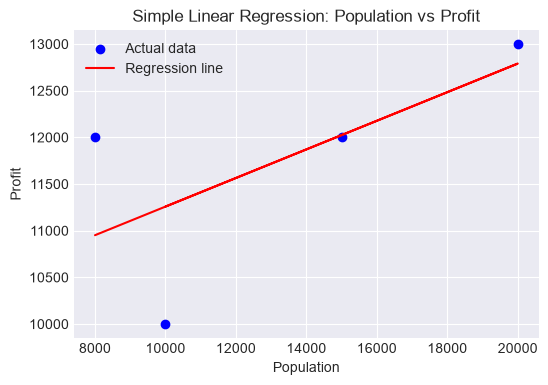

In [8]:
plt.figure(figsize=(6,4))
plt.scatter(known_df['Population'], known_df['Profit'], color='blue', label='Actual data')
plt.plot(known_df['Population'], simple_model.predict(known_df[['Population']]), color='red', label='Regression line')
plt.xlabel('Population')
plt.ylabel('Profit')
plt.title('Simple Linear Regression: Population vs Profit')
plt.legend()
plt.show()

## Task 2: Performance Evaluation (Simple Linear Regression)

In [9]:
simple_mae = mean_absolute_error(y_test, y_pred_simple)
simple_mse = mean_squared_error(y_test, y_pred_simple)
simple_rmse = np.sqrt(simple_mse)
simple_r2 = r2_score(y_test, y_pred_simple)

print('MAE:', simple_mae)
print('MSE:', simple_mse)
print('RMSE:', simple_rmse)
print('R2 Score:', simple_r2)

MAE: 24.193548387096598
MSE: 585.3277835587844
RMSE: 24.193548387096598
R2 Score: nan


c:\Users\krish\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


## Task 3: Multi-Linear Regression

In [10]:
X_multi = known_df[['Population', 'YearsInBusiness']]
y_multi = known_df['Profit']

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.25, random_state=42)

multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)

print('Intercept:', multi_model.intercept_)
print('Coefficients:', multi_model.coef_)

Intercept: -45000.000000000044
Coefficients: [-1.0e+00  1.3e+04]


In [11]:
y_pred_multi = multi_model.predict(X_test_m)

pd.DataFrame({'Actual': y_test_m.values, 'Predicted': y_pred_multi})

,Actual,Predicted
0,12000.0,18000.0


## Task 4: Performance Evaluation (Multi-Linear Regression)

In [12]:
multi_mae = mean_absolute_error(y_test_m, y_pred_multi)
multi_mse = mean_squared_error(y_test_m, y_pred_multi)
multi_rmse = np.sqrt(multi_mse)
multi_r2 = r2_score(y_test_m, y_pred_multi)

print('MAE:', multi_mae)
print('MSE:', multi_mse)
print('RMSE:', multi_rmse)
print('R2 Score:', multi_r2)

MAE: 6000.000000000007
MSE: 36000000.00000009
RMSE: 6000.000000000007
R2 Score: nan


c:\Users\krish\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


## Task 5: Model Comparison and Interpretation

In [13]:
comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multi-Linear Regression'],
    'MAE': [simple_mae, multi_mae],
    'MSE': [simple_mse, multi_mse],
    'RMSE': [simple_rmse, multi_rmse],
    'R2 Score': [simple_r2, multi_r2]
})

comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Simple Linear Regression,24.193548,5.853278e+02,24.193548,NaN
1,Multi-Linear Regression,6000.000000,3.600000e+07,6000.000000,NaN


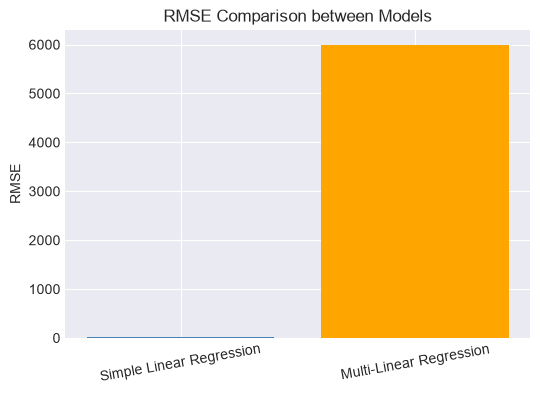

In [14]:
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(comparison['Model'], comparison['RMSE'], color=['steelblue', 'orange'])
ax.set_ylabel('RMSE')
ax.set_title('RMSE Comparison between Models')
plt.xticks(rotation=10)
plt.show()

In [15]:
predicted_profit_simple = simple_model.predict(unknown_df[['Population']])
predicted_profit_multi = multi_model.predict(unknown_df[['Population', 'YearsInBusiness']])

print('Predicted profit (Simple Linear Regression):', predicted_profit_simple[0])
print('Predicted profit (Multi-Linear Regression):', predicted_profit_multi[0])

Predicted profit (Simple Linear Regression): 11564.516129032258
Predicted profit (Multi-Linear Regression): -5000.000000000015
